## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Zoe Edelblum

**Date:** 10/12

In [20]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = {0.125: df0_125, 0.25: df0_25, 0.5: df0_5, 1.0: df1_0, 2.0: df2_0}

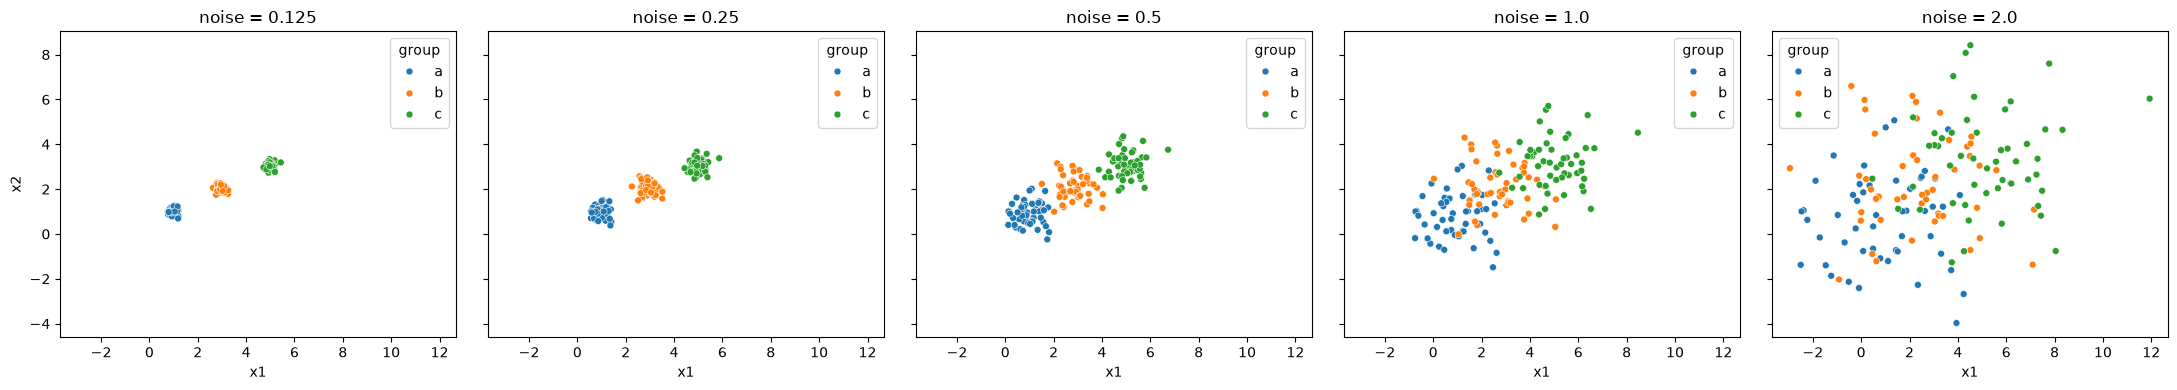

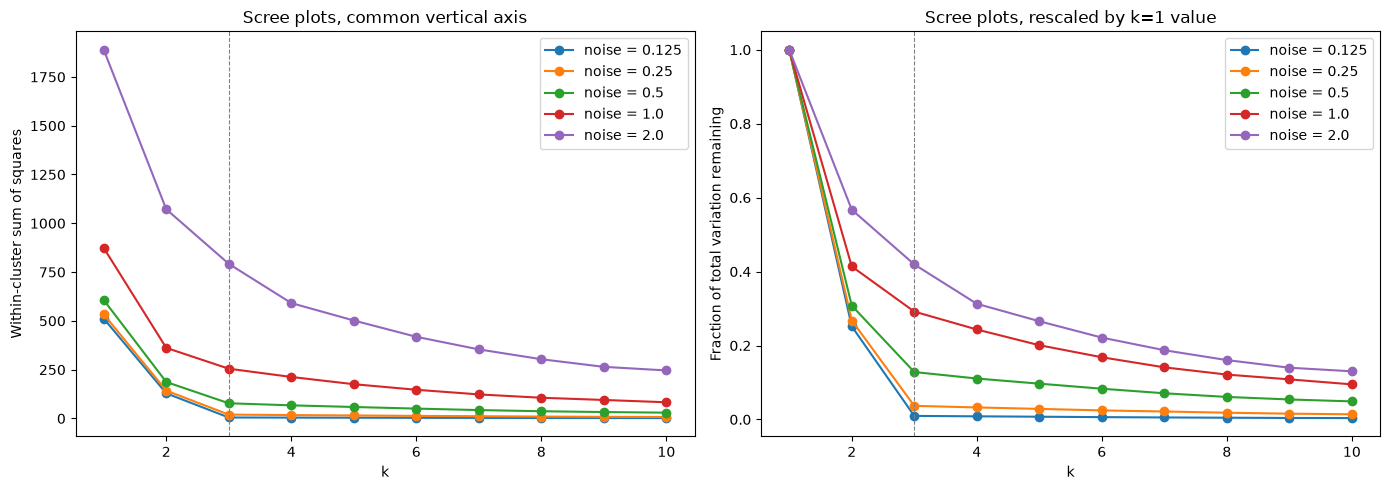

['index', 'Year', 'Country', 'Spending (2020 USD)', 'Percent of GDP', 'Percent of Government Spending', 'Spending per Capita']
(148, 7)
index                               int64
Year                                int64
Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object
(148, 7)


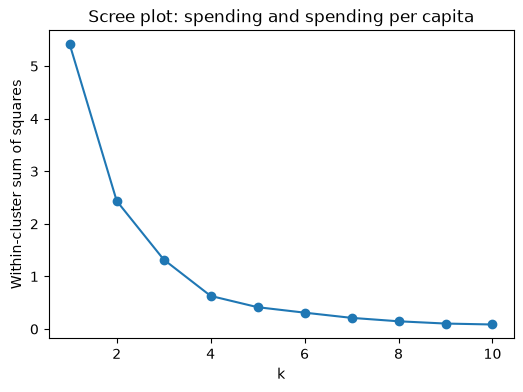

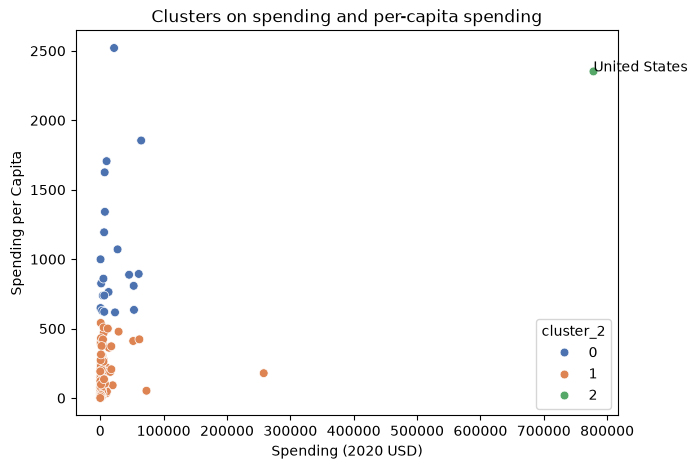

0 21 ['Saudi Arabia', 'United Kingdom', 'Germany', 'France', 'Korea, South', 'Australia', 'Canada', 'Israel']
1 126 ['China', 'India', 'Russia', 'Japan', 'Italy', 'Brazil', 'Turkey', 'Spain']
2 1 ['United States of America']


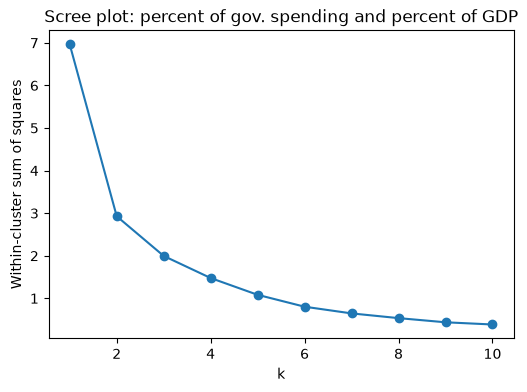

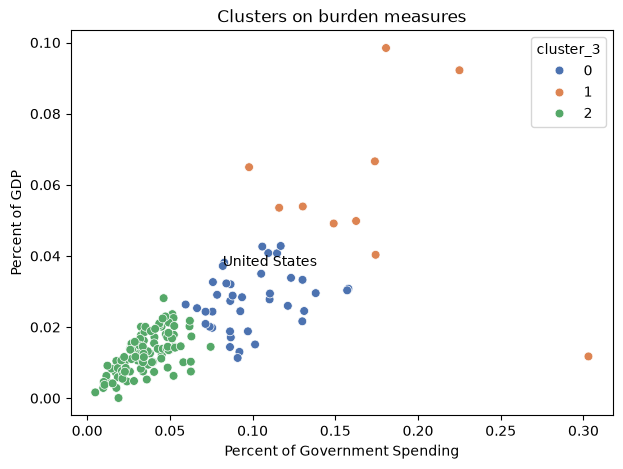

cluster_3                                     0          1          2
Percent of Government Spending count  39.000000  10.000000  99.000000
                               mean    0.098683   0.171289   0.035777
                               std     0.024125   0.058725   0.014549
                               min     0.059520   0.097882   0.004896
                               25%     0.082430   0.135010   0.025921
                               50%     0.092044   0.168248   0.034261
                               75%     0.112633   0.179081   0.047402
                               max     0.157918   0.303027   0.074624
Percent of GDP                 count  39.000000  10.000000  99.000000
                               mean    0.027412   0.058071   0.012664
                               std     0.008191   0.024867   0.005681
                               min     0.011317   0.011742   0.000054
                               25%     0.021254   0.049297   0.008393
                               50%     0.027781   0.053729   0.013191
                               75%     0.032461   0.066190   0.016752
                               max     0.042810   0.098470   0.028132

0 39 ['Morocco', 'Russia', 'Brunei', 'Bahrain', 'Ukraine', 'United States of America', 'Colombia', 'Congo, Republic']
1 10 ['Oman', 'Saudi Arabia', 'Algeria', 'Kuwait', 'Azerbaijan', 'Israel', 'Armenia', 'Jordan']
2 99 ['Greece', 'Estonia', 'Poland', 'Latvia', 'United Kingdom', 'Uruguay', 'Lithuania', 'Serbia']
                       Country  cluster_2  cluster_3
5540  United States of America          2          0


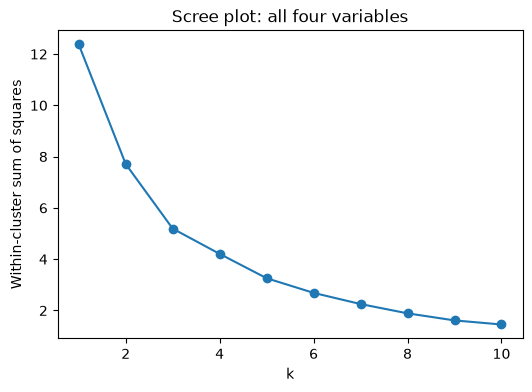

cluster_4                                         0              1  \
Spending (2020 USD)            count      86.000000       6.000000   
                               mean     4513.543790  147964.582042   
                               std     27841.230783  309635.189564   
                               min         8.622460    6095.708713   
                               25%        81.022976    7700.424616   
                               50%       288.061512   15897.570598   
                               75%      1138.618231   53872.942442   
                               max    257973.429834  778397.200000   
Spending per Capita            count      86.000000       6.000000   
                               mean       70.290644    1875.150751   
                               std        81.690590     489.800206   
                               min         0.580129    1193.598730   
                               25%        11.522275    1645.301864   
                               50%        34.845855    1780.059564   
                               75%        95.985387    2227.318999   
                               max       314.201312    2520.398541   
Percent of Government Spending count      86.000000       6.000000   
                               mean        0.043199       0.135351   
                               std         0.021512       0.055392   
                               min         0.004896       0.081976   
                               25%         0.028414       0.101034   
                               50%         0.040096       0.113271   
                               75%         0.053006       0.164503   
                               max         0.101501       0.225050   
Percent of GDP                 count      86.000000       6.000000   
                               mean        0.012481       0.062634   
                               std         0.005799       0.028275   
                               min         0.000054       0.029429   
                               25%         0.007811       0.041272   
                               50%         0.012532       0.059257   
                               75%         0.016783       0.085398   
                               max         0.026340       0.098470   

cluster_4                                        2             3  
Spending (2020 USD)            count     30.000000     26.000000  
                               mean    9073.543709  15330.618681  
                               std    18135.032885  18923.469359  
                               min      163.926877    405.790494  
                               25%      522.737081   3176.345598  
                               50%     1663.090134   5857.060906  
                               75%     8646.648849  21818.934764  
                               max    72937.064048  60675.039625  
Spending per Capita            count     30.000000     26.000000  
                               mean     215.920971    612.677541  
                               std      261.610456    241.189507  
                               min       18.297119    362.467076  
                               25%       46.200403    413.682029  
                               50%      137.955585    579.004604  
                               75%      219.021206    738.120108  
                               max      998.966186   1341.058851  
Percent of Government Spending count     30.000000     26.000000  
                               mean       0.123701      0.033280  
                               std        0.044494      0.011771  
                               min        0.076005      0.011613  
                               25%        0.092832      0.026028  
                               50%        0.115883      0.032077  
                               75%        0.136403      0.044645  
                               max        0.303027      0.052209  
Percent of GDP

0 86 ['China', 'Brazil', 'Turkey', 'Indonesia', 'Mexico', 'Thailand', 'Chile', 'Romania']
1 6 ['United States of America', 'Saudi Arabia', 'Israel', 'Singapore', 'Kuwait', 'Oman']
2 30 ['India', 'Russia', 'Korea, South', 'Iran', 'Taiwan', 'Pakistan', 'Algeria', 'Colombia']
3 26 ['United Kingdom', 'Germany', 'France', 'Japan', 'Italy', 'Australia', 'Canada', 'Spain']


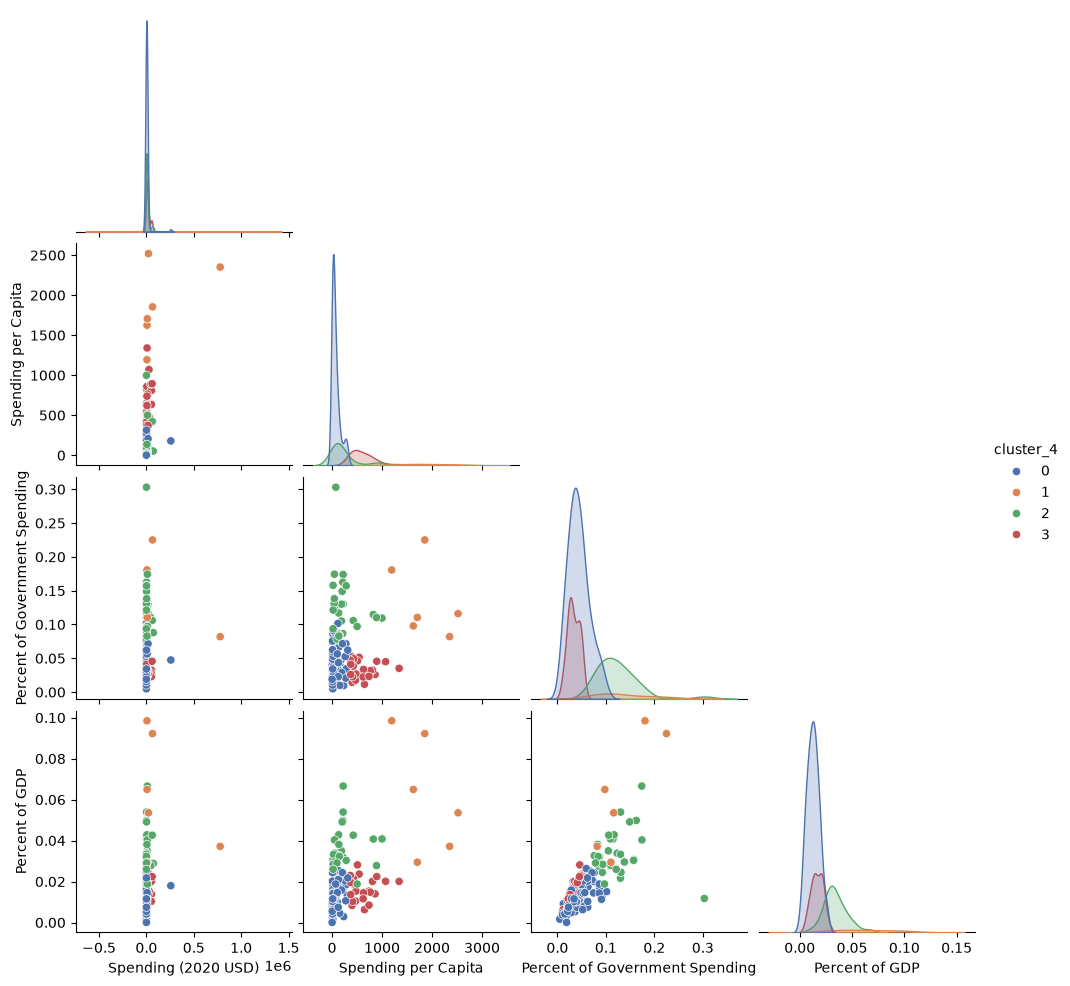

4-var          0  1   2   3
2-var (size)               
0              0  5   3  13
1             86  0  27  13
2              0  1   0   0
4-var            0  1   2   3
2-var (burden)               
0               13  2  24   0
1                0  4   6   0
2               73  0   0  26


In [22]:
#Q1.2
fig, axes = plt.subplots(1, 5, figsize=(22, 4), sharex=True, sharey=True)
for ax, (noise, d) in zip(axes, datasets.items()):
    sns.scatterplot(data=d, x='x1', y='x2', hue='group', ax=ax, s=25)
    ax.set_title(f'noise = {noise}')
plt.tight_layout()
plt.show()

#Q1.3
def scree(X, kmax=10):
    inertias = []
    for k in range(1, kmax + 1):
        km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
        inertias.append(km.inertia_)
    return np.array(inertias)

ks = np.arange(1, 11)
curves = {noise: scree(d[['x1', 'x2']].values) for noise, d in datasets.items()}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for noise, inertia in curves.items():
    axes[0].plot(ks, inertia, marker='o', label=f'noise = {noise}')
    axes[1].plot(ks, inertia / inertia[0], marker='o', label=f'noise = {noise}')
axes[0].set_title('Scree plots, common vertical axis')
axes[0].set_ylabel('Within-cluster sum of squares')
axes[1].set_title('Scree plots, rescaled by k=1 value')
axes[1].set_ylabel('Fraction of total variation remaining')
for ax in axes:
    ax.set_xlabel('k')
    ax.axvline(3, color='gray', ls='--', lw=0.8)
    ax.legend()
plt.tight_layout()
plt.show()

pd.DataFrame(curves, index=ks).round(1)

def minmax(s):
    return (s - s.min()) / (s.max() - s.min())

def scree_plot(X, kmax=10, title=''):
    inertias = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_
                for k in range(1, kmax + 1)]
    plt.figure(figsize=(6, 4))
    plt.plot(range(1, kmax + 1), inertias, marker='o')
    plt.xlabel('k'); plt.ylabel('Within-cluster sum of squares')
    plt.title(title)
    plt.show()

def run_kmeans(data, cols, k, label):
    X = data[cols].apply(minmax)
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    data[label] = km.labels_
    return km

def cluster_scatter(data, x, y, label, title=''):
    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=data, x=x, y=y, hue=label, palette='deep', s=40)
    for _, r in data[data['Country'].isin(['United States of America', 'United States', 'USA'])].iterrows():
        plt.annotate('United States', (r[x], r[y]))
    plt.title(title)
    plt.show()

#Q2.1
raw = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')
print(raw.columns.tolist())

df = raw.loc[raw['Year'] == 2020].dropna().copy()
print(df.shape)
print(df.dtypes)
df.head()

num_vars = ['Spending (2020 USD)', 'Spending per Capita',
            'Percent of Government Spending', 'Percent of GDP']

for v in num_vars:
    if df[v].dtype == object:
        df[v] = pd.to_numeric(df[v].astype(str).str.replace(r'[$,%]', '', regex=True), errors='coerce')
df = df.dropna(subset=num_vars)

print(df.shape)
df[num_vars].describe()

#Q2.2
cols2 = ['Spending (2020 USD)', 'Spending per Capita']
scree_plot(df[cols2].apply(minmax), title='Scree plot: spending and spending per capita')
k2 = 3
run_kmeans(df, cols2, k2, 'cluster_2')
cluster_scatter(df, cols2[0], cols2[1], 'cluster_2', 'Clusters on spending and per-capita spending')
df.groupby('cluster_2')[cols2].describe().T
for c, g in df.groupby('cluster_2'):
    print(c, len(g), g.sort_values(cols2[0], ascending=False)['Country'].head(8).tolist())

#Q2.3
cols3 = ['Percent of Government Spending', 'Percent of GDP']
scree_plot(df[cols3].apply(minmax), title='Scree plot: percent of gov. spending and percent of GDP')
k3 = 3
run_kmeans(df, cols3, k3, 'cluster_3')
cluster_scatter(df, cols3[0], cols3[1], 'cluster_3', 'Clusters on burden measures')
display(df.groupby('cluster_3')[cols3].describe().T)
for c, g in df.groupby('cluster_3'):
    print(c, len(g), g.sort_values(cols3[1], ascending=False)['Country'].head(8).tolist())
print(df.loc[df['Country'].isin(['United States of America', 'United States']), ['Country', 'cluster_2', 'cluster_3']])

#Q2.4
scree_plot(df[num_vars].apply(minmax), title='Scree plot: all four variables')
k4 = 4
run_kmeans(df, num_vars, k4, 'cluster_4')
display(df.groupby('cluster_4')[num_vars].describe().T)
for c, g in df.groupby('cluster_4'):
    print(c, len(g), g.sort_values(num_vars[0], ascending=False)['Country'].head(8).tolist())

sns.pairplot(df, vars=num_vars, hue='cluster_4', palette='deep', corner=True)
plt.show()

print(pd.crosstab(df['cluster_2'], df['cluster_4'], rownames=['2-var (size)'], colnames=['4-var']))
print(pd.crosstab(df['cluster_3'], df['cluster_4'], rownames=['2-var (burden)'], colnames=['4-var']))

**Q1.**

1. The code creates five datasets (df0_125, df0_25, df0_5, df1_0, df2_0) with three groups centered at (1,1), (3,2) and (5,3). Only the noise (standard deviation) changes between them.

2. At noise = 0.125 and 0.25 the three groups are tight, well-separated blobs. At 0.5 the edges of neighboring groups begin to touch. At 1.0 the clusters visibly overlap, and by 2.0 the points form one large smear in which the three groups are barely distinguishable by eye. The cluster centers never move, but as the standard deviation grows relative to the distance between centers (about 2.2 units), the clusters lose their visual distinctness.

3. On a common vertical axis, the whole scree curve shifts up as noise rises, because within-cluster variation scales with the noise variance. With noise = 0.125 and 0.25 there is a sharp elbow at k = 3: the drop from k = 2 to k = 3 is large and every later drop is negligible. At 0.5 the elbow is softer, at 1.0 it is hard to pinpoint, and at 2.0 the curve is a smooth, gently convex decline with no obvious kink. The fraction of variation remaining at k = 3 is roughly 0.01, 0.04, 0.13, 0.29 and 0.42 as noise goes from 0.125 to 2.0. For low noise, k = 3 is unambiguous. For high noise, k = 2, 3 or 4 all look defensible, so the scree plot cannot definitively select k.

**Q2.**

1. After filtering to 2020 and dropping missing rows there are 148 countries, and all four variables loaded as float64, so no type conversion or string cleaning is needed. The index and Year columns are not used in the clustering. Two features of the data matter later but are not errors: Spending (2020 USD) is extremely right-skewed (the US is about $778B, while the median country is a few hundred million), and the percent variables are stored as fractions (0.03 = 3%), which does not matter after min-max scaling.

2. The scree plot bends around k = 3 to 4. I used k = 3. The three clusters are:
   - **Cluster 2 (1 country):** the United States, alone. Its spending ($778B) is so far above everyone else that after min-max scaling it sits at 1.0 on the x-axis.
   - **Cluster 0 (21 countries):** high per-capita spenders (Saudi Arabia, UK, Germany, France, South Korea, Australia, Canada, Israel), at roughly $600 to $2,500 per person.
   - **Cluster 1 (126 countries):** everyone else, including China, India, Russia, Japan and Brazil, with low per-capita spending.

   Almost all the separation comes from per-capita spending, because total spending is dominated by one point. China (about $258B) lands in the low cluster since its per-capita spending (about $180) is low and the US squashes the scale. The algorithm is mostly isolating an outlier and then splitting the rest by per-capita spending.

3. The elbow is soft, around k = 3. I used k = 3. The clusters are:
   - **Cluster 2 (99 countries):** low burden (mean 3.6% of government spending, 1.3% of GDP), mostly European and wealthy or stable countries (Greece, Estonia, Poland, UK, Uruguay).
   - **Cluster 0 (39 countries):** moderate burden (about 9.9% of government spending, 2.7% of GDP), including Russia, Ukraine, Morocco, Colombia and the United States.
   - **Cluster 1 (10 countries):** high burden (about 17% of government spending, 5.8% of GDP): Oman, Saudi Arabia, Algeria, Kuwait, Azerbaijan, Israel, Armenia, Jordan.

   Compared with part 2, the United States is no longer an outlier: it spends the most in dollars but is mid-range as a share of GDP (about 3.7%) and of the budget (about 8%). The two variables are strongly correlated, so the clusters are bands along an upward diagonal. This clustering groups countries by how much of their economy and budget the military consumes, rather than by size.

4. The scree plot elbow is ambiguous (between k = 3 and 5). I used k = 4. The clusters are:
   - **Cluster 0 (86 countries):** low on everything (about $70 per capita, 1.2% of GDP), including China, Brazil, Turkey, Indonesia and Mexico.
   - **Cluster 3 (26 countries):** wealthy moderate spenders (about $613 per capita but only 1.7% of GDP): UK, Germany, France, Japan, Italy, Australia, Canada, Spain.
   - **Cluster 2 (30 countries):** high burden, mid per-capita (12% of government spending, 3.4% of GDP, about $216 per capita): India, Russia, South Korea, Iran, Taiwan, Pakistan, Algeria, Colombia.
   - **Cluster 1 (6 countries):** high per capita and high burden (about $1,875 per capita, 6.3% of GDP): United States, Saudi Arabia, Israel, Singapore, Kuwait, Oman.

   The four-variable result combines the two earlier stories and refines both. The 126-country cluster from part 2 splits into 86 / 27 / 13 by burden and wealth, and the 99-country low-burden cluster from part 3 splits into 73 / 26 by per-capita spending. Total dollars barely matter here, since only the US stands out on that axis, so China is grouped with the low-intensity countries.

5. Partly yes. The four-variable clustering is the most informative because it gives an interpretable typology: low-intensity countries, wealthy moderate spenders, high-burden security-driven states, and small high-spending states (Gulf, Singapore, US). The burden-based clustering also shows that the US, while huge in dollars, is not unusual relative to its economy. The limitations are:
   - The scree plots show no crisp elbow, so the choice of k is subjective.
   - Min-max scaling on heavily skewed dollar spending lets one point (the US) dominate, so a whole cluster is spent on a single country. A log transform would likely help.
   - K-means assumes roughly round, similar-sized clusters, which this data does not have (clusters range from 1 to 126 countries).
   - The clusters need outside knowledge to interpret.

   Overall it is a useful exploratory tool, not evidence of firm categories.

6. The scree plot graphs within-cluster sum of squares (WCSS) against k. Adding a cluster can never increase WCSS, so the curve always falls. The question is how much each additional cluster buys. In the simulation the data come from three true groups. Going from k = 1 to 2 to 3 separates groups that are far apart, which removes a large amount of variation, so the curve drops steeply. Once k = 3, each cluster already holds one natural group, so extra clusters only split a blob into arbitrary pieces and remove little variation, and the curve flattens. The bend between steep and flat is the elbow, here at k = 3, the true number of groups. It marks diminishing returns. Noise blurs it: when the spread within groups is small relative to the distance between centers, the bend is sharp, but when the spread is comparable to that distance, splitting a blob gains almost as much as separating groups. The curve then declines smoothly and the elbow disappears, as in the noise = 1.0 and 2.0 scree plots.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]